# Visualization

Inspect spatial fields with synchronized position, pose, heading, and events;
export a portable HTML player; and register a synthetic video to arena units.
The default run creates static previews and a modest HTML animation. Desktop
viewers, widgets, and video exports require an explicit opt-in.

**Estimated time**: 15-20 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb).

No private assets or video packages are needed for the default path. The
synthetic RGB video stays in memory. Reading a video file instead requires
`neurospatial[video]`; desktop/widget viewers use `neurospatial[animation]`.

In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.transforms import Affine2D as MplAffine2D

from neurospatial import Environment
from neurospatial.animation import (
    BodypartOverlay,
    EventOverlay,
    HeadDirectionOverlay,
    PositionOverlay,
    Skeleton,
    VideoOverlay,
)
from neurospatial.ops.transforms import VideoCalibration, calibrate_from_landmarks

RUN_NAPARI = False
RUN_WIDGET = False
RUN_VIDEO_EXPORT = False
EMBED_HTML = True

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(10, 5))
artifacts = tempfile.TemporaryDirectory(prefix="neurospatial-visualization-")
output_dir = Path(artifacts.name)

## 1. Create a small, synchronized scene

Sixteen frames at 8 Hz span two seconds of presentation. Timestamps run from
0 to 1.875 s; every overlay uses that same clock. Coordinates are `(x, y)` in
centimeters, with zero heading East and positive angles toward North.

The moving Gaussian is a visualization fixture in arbitrary units, rather
than a fitted rate map or decoded probability. Synthetic pose follows the
trajectory tangent; real body orientation need not equal movement direction.

In [2]:
env = Environment.from_grid_mask(
    np.ones((20, 20), dtype=bool),
    grid_edges=(np.arange(0, 105, 5.0), np.arange(0, 105, 5.0)),
)
env.units = "cm"
env.regions.add("reference", point=np.array([50.0, 50.0]))
n_frames, fps = 16, 8.0
frame_times = np.arange(n_frames) / fps
phase = 2 * np.pi * np.arange(n_frames) / n_frames
trajectory = np.column_stack([50 + 25 * np.cos(phase), 50 + 25 * np.sin(phase)])
heading = phase + np.pi / 2
direction = np.column_stack([np.cos(heading), np.sin(heading)])
pose = {
    "nose": trajectory + 4 * direction,
    "body": trajectory,
    "tail": trajectory - 4 * direction,
}
skeleton = Skeleton(
    name="synthetic_pose",
    nodes=("nose", "body", "tail"),
    edges=(("nose", "body"), ("body", "tail")),
    edge_color="white",
    edge_width=2.0,
)
offsets = env.bin_centers[None, :, :] - trajectory[:, None, :]
fields = np.exp(-np.sum(offsets**2, axis=-1) / (2 * 12.0**2))
view_settings = {"frame_times": frame_times, "cmap": "magma", "vmin": 0, "vmax": 1}
print(f"Fields: {fields.shape}; in-memory field data: {fields.nbytes / 1e6:.2f} MB")

Fields: (16, 400); in-memory field data: 0.05 MB


## 2. Check static frames before animating

Use the same color limits for every frame. A changing automatic scale can
make a stable signal appear to change amplitude. Pass overlay coordinates
in environment order; backends handle their own display conventions.

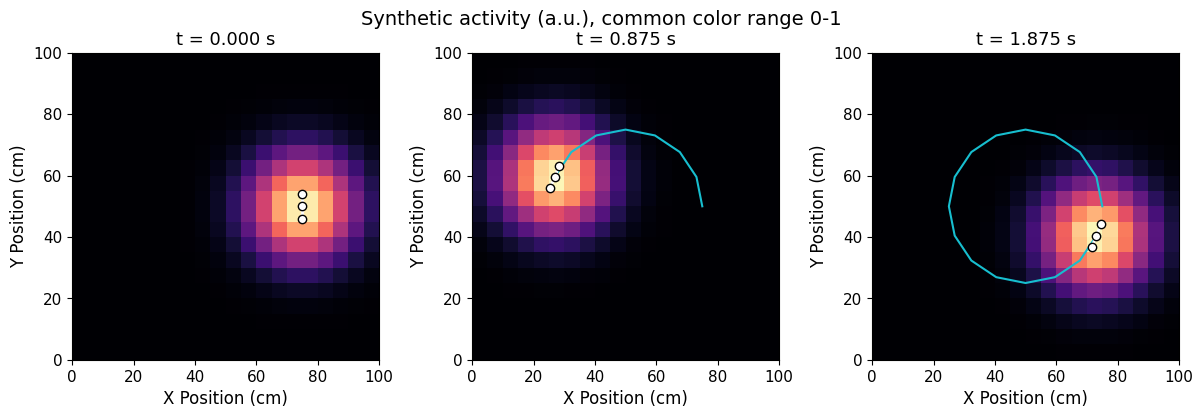

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, index in zip(axes, [0, 7, 15], strict=True):
    env.plot_field(fields[index], ax=ax, vmin=0, vmax=1, colorbar=False, cmap="magma")
    ax.plot(trajectory[: index + 1, 0], trajectory[: index + 1, 1], color="tab:cyan")
    points = np.array([pose[name][index] for name in ("tail", "body", "nose")])
    ax.plot(points[:, 0], points[:, 1], "wo-", lw=2, markeredgecolor="black")
    ax.set_title(f"t = {frame_times[index]:.3f} s")
fig.suptitle("Synthetic activity (a.u.), common color range 0-1")
plt.show()

## 3. Export a shareable HTML player

HTML supports positions and trails, pose skeletons, heading arrows, fading
events, and regions. These overlays are baked into frame images in both embed
modes. Video and time-series overlays are currently unsupported by HTML and
trigger explicit warnings, so they are omitted from this export.

`EMBED_HTML=True` makes one self-contained file. Set it to False for external
PNG frames; distribute that HTML together with its sibling frames directory.
Both modes retain the frame limit. For larger recordings, select frames with
matching timestamps and subset the overlays consistently before export.

In [4]:
overlays = [
    PositionOverlay(
        trajectory, times=frame_times, color="cyan", size=5, trail_length=5
    ),
    BodypartOverlay(pose, times=frame_times, skeleton=skeleton),
    HeadDirectionOverlay(heading, times=frame_times, length=10.0, color="yellow"),
    EventOverlay(
        event_times=frame_times[[4, 12]],
        event_positions=trajectory[[4, 12]],
        colors="lime",
        size=9,
        decay_frames=4,
    ),
]
html_path = env.animate_fields(
    fields,
    overlays=overlays,
    show_regions=True,
    backend="html",
    save_path=str(output_dir / "spatial_scene.html"),
    embed=EMBED_HTML,
    n_workers=2,
    dpi=60,
    frame_labels=[f"t = {time:.3f} s" for time in frame_times],
    **view_settings,
)
print(f"HTML export: {html_path} ({html_path.stat().st_size / 1e6:.2f} MB)")
if "get_ipython" in globals() and EMBED_HTML:
    from IPython.display import HTML, display

    display(HTML(filename=str(html_path)))

Encoding frames:   0%|          | 0/16 [00:00<?, ?it/s]

Encoding frames:  38%|███▊      | 6/16 [00:00<00:00, 48.38it/s]

Encoding frames:  88%|████████▊ | 14/16 [00:00<00:00, 62.26it/s]

Encoding frames: 100%|██████████| 16/16 [00:00<00:00, 61.09it/s]

HTML export: /var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/neurospatial-visualization-nsep7p2x/spatial_scene.html (0.24 MB)


## 4. Register raw video pixels to the arena

Video uses `(column, row)` pixels with row increasing downward. Corresponding
arena landmarks use `(x, y)` centimeters with y increasing upward. The fitted
transform includes the Y flip: pass raw pixel coordinates without flipping
them first. Landmarks also locate the translated arena origin; a scale bar
alone determines scale, rather than full registration.

Our exact, axis-aligned synthetic geometry is deliberately simple. Small fit
residuals do not validate a real camera model; use held-out landmarks and
account for perspective or distortion when needed.

In [5]:
width, height = 160, 120
landmarks_px = np.array([[20, 10], [120, 10], [120, 110], [20, 110]], dtype=float)
landmarks_cm = np.array([[0, 100], [100, 100], [100, 0], [0, 0]], dtype=float)
transform = calibrate_from_landmarks(
    landmarks_px, landmarks_cm, frame_size_px=(width, height), kind="similarity"
)
calibration = VideoCalibration(transform, frame_size_px=(width, height))
np.testing.assert_allclose(transform(landmarks_px), landmarks_cm, atol=1e-10)
np.testing.assert_allclose(
    transform(np.array([[70.0, 60.0]])), [[50.0, 50.0]], atol=1e-10
)
pixels = transform.inverse()(trajectory)
rows, columns = np.mgrid[:height, :width]
video_frames = np.full((n_frames, height, width, 3), 35, dtype=np.uint8)
video_frames[:, 10:111, 20:121] = 75
for index, (column, row) in enumerate(pixels):
    marker = (columns - column) ** 2 + (rows - row) ** 2 <= 3**2
    video_frames[index, marker] = [255, 180, 0]
print(f"Synthetic video array: {video_frames.nbytes / 1e6:.2f} MB")

Synthetic video array: 0.92 MB


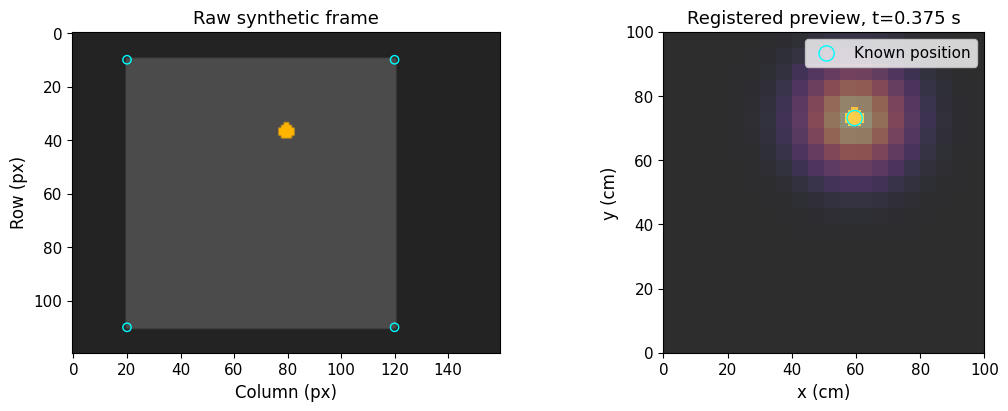

In [6]:
index = 3
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].imshow(video_frames[index])
axes[0].scatter(
    landmarks_px[:, 0], landmarks_px[:, 1], facecolors="none", edgecolors="cyan"
)
axes[0].set(xlabel="Column (px)", ylabel="Row (px)", title="Raw synthetic frame")
# Pixel centers are integer (column, row) coordinates. Apply the complete
# affine mapping to those centers, including Y reflection and any rotation.
axes[1].imshow(
    video_frames[index],
    origin="upper",
    extent=[-0.5, width - 0.5, height - 0.5, -0.5],
    transform=MplAffine2D(transform.A) + axes[1].transData,
)
env.plot_field(
    fields[index], ax=axes[1], alpha=0.4, colorbar=False, vmin=0, vmax=1, cmap="magma"
)
axes[1].scatter(
    *trajectory[index],
    facecolors="none",
    edgecolors="cyan",
    s=120,
    label="Known position",
)
axes[1].set(
    xlabel="x (cm)",
    ylabel="y (cm)",
    title=f"Registered preview, t={frame_times[index]:.3f} s",
)
axes[1].set_aspect("equal")
axes[1].legend()
plt.show()

## 5. Optional viewers and final video export

Re-run this cell after setting a flag in Setup. Napari needs a working desktop
and the animation extra; widgets need Jupyter and ipywidgets. Video export
needs an `ffmpeg` executable. These paths are opt-in and are not exercised by
the default run. Use explicit backend names so installing a GUI package does
not change the notebook's behavior.

A `VideoOverlay` may read a file lazily or accept this small RGB array. Supply
the source video timestamps on the same clock as `frame_times`. A video placed
below an opaque field will be hidden; use transparency or place it above.

In [7]:
video_overlay = VideoOverlay(
    source=video_frames,
    times=frame_times,
    calibration=calibration,
    alpha=0.45,
    z_order="above",
)
if RUN_NAPARI:
    import napari

    viewer = env.animate_fields(
        fields,
        overlays=[*overlays, video_overlay],
        backend="napari",
        **view_settings,
    )
    if "get_ipython" not in globals():
        napari.run()

if RUN_WIDGET:
    env.animate_fields(fields, overlays=overlays, backend="widget", **view_settings)

if RUN_VIDEO_EXPORT:
    from neurospatial.animation.backends.video_backend import check_ffmpeg_available

    if not check_ffmpeg_available():
        raise RuntimeError(
            "Install the ffmpeg executable before enabling RUN_VIDEO_EXPORT."
        )
    env.clear_cache()
    env.animate_fields(
        fields,
        overlays=[*overlays, video_overlay],
        backend="video",
        save_path=str(output_dir / "spatial_scene.mp4"),
        n_workers=2,
        dpi=80,
        **view_settings,
    )

print(
    f"Optional flags: napari={RUN_NAPARI}, widget={RUN_WIDGET}, video={RUN_VIDEO_EXPORT}"
)

Optional flags: napari=False, widget=False, video=False


HTML artifacts live in a temporary directory while this kernel is running;
copy them to a chosen location to keep or share them. Save analysis results
independently of rendered images with [NWB I/O](09_nwb_io.ipynb). The
[Position decoding](06_position_decoding.ipynb) workflow provides an example
of meaningful spatial probability fields to visualize.